# Choosing the D3 Penalty Strength

This notebook starts from the experimental D3 sweep: adding a derivative penalty visibly stabilizes the extracted experimental barriers. It then uses a controlled single-curve toy problem, where the true barrier is known, to compare candidate penalty strengths in a more principled way.

Experimental results are read from `data/results/experiments8_d3_sweep`; toy sweep results are read from `data/results/d3_sweep_single_curve`.


In [1]:
import os
import sys
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    import scienceplots
    plt.style.use(["science", "notebook", "ieee", "grid"])
except ModuleNotFoundError:
    plt.style.use("default")

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 11,
    "axes.labelsize": 18,
    "axes.titlesize": 17,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 10,
    "mathtext.fontset": "cm",
    "axes.linewidth": 1.2,
    "lines.linewidth": 2.0,
})



def find_project_root(start):
    for base in [start, *start.parents]:
        for candidate in [base, base / "barrier-extraction"]:
            if (candidate / "src").is_dir() and (candidate / "data").is_dir():
                return candidate
    raise FileNotFoundError("Could not locate barrier-extraction project root containing src/ and data/.")

REPO_ROOT = find_project_root(Path.cwd().resolve())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
SRC = REPO_ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))


from utils import paper_three_point_barrier
from train import percentile_bands

path_base = REPO_ROOT / 'data' / 'results' / 'experiments8_d3_sweep'

save_dir = Path("../../plots")#path_base / 'plots'
save_dir.mkdir(parents=True, exist_ok=True)

DE_STENCIL = 2

titles = (
    '16O208PbMorton1999',
    '40Ca40CaMontagnoli2012',
    '48Ca40CaJiang2010',
    '48Ca48CaStefanini2009',
)

reaction_labels = [
    r'$^{16}\mathrm{O} + ^{208}\mathrm{Pb}$',
    r'$^{40}\mathrm{Ca} + ^{40}\mathrm{Ca}$',
    r'$^{48}\mathrm{Ca} + ^{40}\mathrm{Ca}$',
    r'$^{48}\mathrm{Ca} + ^{48}\mathrm{Ca}$',
]

ylims = {
    '16O208PbMorton1999': (-100, 1000),
    '40Ca40CaMontagnoli2012': (-100, 2000),
    '48Ca40CaJiang2010': (-100, 1000),
    '48Ca48CaStefanini2009': (-100, 1500),
}

selected_sub_indices = {
    '16O208PbMorton1999': 5,
    '40Ca40CaMontagnoli2012': 6,
    '48Ca40CaJiang2010': 2,
    '48Ca48CaStefanini2009': 8,
}

weak_lambda_specs = [
    ('0', '0.0'),
    ('1e-6', '1e-6'),
    ('1e-4', '1e-4'),
    ('1e-2', '1e-2'),
]

strong_lambda_specs = [
    ('1e-1', '1e-1'),
    ('1', '1.0'),
    ('1e2', '1e2'),
    ('1e3', '1e3'),
]

all_lambda_specs = weak_lambda_specs + strong_lambda_specs

lambda_colors = {
    '0.0': 'black',
    '1e-6': '#1f77b4',
    '1e-4': '#2ca02c',
    '1e-2': '#d62728',
    '1e-1': '#9467bd',
    '1.0': '#8c564b',
    '1e2': '#e377c2',
    '1e3': '#7f7f7f',
}

lambda_linestyles = {
    '0.0': '--',
    '1e-6': '--',
    '1e-4': '--',
    '1e-2': '--',
    '1e-1': '--',
    '1.0': '--',
    '1e2': '--',
    '1e3': '--',
}

lambda_display_labels = {
    '0.0': r'$0$',
    '1e-6': r'$10^{-6}$',
    '1e-4': r'$10^{-4}$',
    '1e-2': r'$10^{-2}$',
    '1e-1': r'$10^{-1}$',
    '1.0': r'$1$',
    '1e2': r'$10^{2}$',
    '1e3': r'$10^{3}$',
}

lambda_line_alpha = 0.88
lambda_line_width = 2.8

plt.rcParams.update({
    'figure.dpi': 120,
    'savefig.dpi': 300,
    'axes.grid': True,
    'grid.alpha': 0.22,
    'axes.linewidth': 1.2,
})

/opt/software-current/2023.06/x86_64/intel/skylake_avx512/software/Python-bundle-PyPI/2023.06-GCCcore-12.3.0/lib/python3.11/site-packages/pyparsing/core.py:5596: SyntaxWarning: 'return' in a 'finally' block
  return self.__class__.__name__ + ": " + retString


In [2]:
def merged_h5_path(title, lambda_tag):
    return path_base / f'experiments_{title}_bnn_soc_d3lam_{lambda_tag}.h5_8x1000_lognormal_soc_d3lam_{lambda_tag}'


def available_group_names(h5_path):
    with h5py.File(h5_path, 'r') as f:
        return sorted(f.keys())


def choose_group_name(h5_path, dataset_idx, preferred_sub_index):
    preferred = f'{int(dataset_idx):05d}_run{int(preferred_sub_index):02d}'
    groups = available_group_names(h5_path)
    if preferred in groups:
        return preferred, False, len(groups)
    if not groups:
        raise ValueError(f'No groups found in {h5_path}')
    return groups[0], True, len(groups)


def load_panel_payload(dataset_idx, title, lambda_tag, preferred_sub_index):
    h5_path = merged_h5_path(title, lambda_tag)
    group_name, used_fallback, num_groups = choose_group_name(h5_path, dataset_idx, preferred_sub_index)

    with h5py.File(h5_path, 'r') as f:
        grp = f[group_name]
        x = grp['x_pred'][:]
        y_samples = grp['y_samples'][:]
        D_samples = grp['d2_samples'][:]
        E_data = grp['E_data'][:]
        Sigma_data = grp['Sigma_data'][:]
        Sigma_err = grp['Sigma_err'][:]

    D_mean = D_samples.mean(axis=0)
    bands = percentile_bands(D_samples, levels=(0.68,))
    D_lo = bands['lower_68']
    D_hi = bands['upper_68']

    E_pts, D_pts, D_pts_err = paper_three_point_barrier(
        E_data, Sigma_data, Sigma_err, dE=DE_STENCIL
    )

    return {
        'h5_path': str(h5_path),
        'group_name': group_name,
        'used_fallback': used_fallback,
        'num_groups': num_groups,
        'x': x,
        'y_samples': y_samples,
        'D_samples': D_samples,
        'D_mean': D_mean,
        'D_lo': D_lo,
        'D_hi': D_hi,
        'E_data': E_data,
        'Sigma_data': Sigma_data,
        'Sigma_err': Sigma_err,
        'E_pts': E_pts,
        'D_pts': D_pts,
        'D_pts_err': D_pts_err,
    }


def plot_barrier_panel(ax, payload, title_text, ylim, color='red', show_legend=False):
    x = payload['x']
    E_data = payload['E_data']
    E_pts = payload['E_pts']
    D_mean = payload['D_mean']
    D_lo = payload['D_lo']
    D_hi = payload['D_hi']
    D_pts = payload['D_pts']
    D_pts_err = payload['D_pts_err']

    line, = ax.plot(x, D_mean, '--', color=color, linewidth=2.0, label='AutoBNN mean')
    band = ax.fill_between(x, D_lo, D_hi, color=color, alpha=0.20, label='AutoBNN 68% CI')
    pts = ax.errorbar(
        E_pts,
        D_pts,
        yerr=D_pts_err,
        fmt='o',
        color='black',
        ms=8,
        lw=2,
        capsize=3,
        label='3-point formula',
    )

    ax.set_xlim(E_data.min(), E_data.max())
    ax.set_ylim(ylim)
    ax.set_title(title_text)
    if show_legend:
        ax.legend(
            [line, band, pts],
            ['AutoBNN mean', 'AutoBNN 68% CI', '3-point formula'],
            loc='upper right',
            frameon=False,
            fontsize=10,
        )


def build_grid(lambda_specs, figure_stem):
    records = []
    fig, axes = plt.subplots(len(lambda_specs), 4, figsize=(17, 3.8 * len(lambda_specs)), sharex=False, layout='constrained')

    if len(lambda_specs) == 1:
        axes = np.asarray([axes])

    for row_idx, (lambda_tag, lambda_label) in enumerate(lambda_specs):
        for col_idx, (title, rxn_label) in enumerate(zip(titles, reaction_labels)):
            ax = axes[row_idx, col_idx]
            payload = load_panel_payload(col_idx, title, lambda_tag, selected_sub_indices[title])
            panel_title = f'{rxn_label}\n$\\lambda_{{d3}}={lambda_label}$'
            plot_barrier_panel(
                ax=ax,
                payload=payload,
                title_text=panel_title,
                ylim=ylims[title],
                color=lambda_colors[lambda_label],
                show_legend=(row_idx == 0 and col_idx == 0),
            )

            ax.grid(True, alpha=0.25)
            ax.tick_params(labelsize=12)
            ax.text(
                0.03, 0.95, f'({chr(97 + row_idx * len(titles) + col_idx)})',
                transform=ax.transAxes,
                ha='left',
                va='top',
                fontsize=11,
            )

            records.append({
                'dataset_idx': col_idx,
                'dataset': title,
                'reaction_label': rxn_label,
                'd3_lambda_tag': lambda_tag,
                'd3_lambda_label': lambda_label,
                'preferred_run': selected_sub_indices[title],
                'chosen_group_name': payload['group_name'],
                'used_fallback_group': payload['used_fallback'],
                'num_available_groups': payload['num_groups'],
                'num_barrier_samples': int(payload['D_samples'].shape[0]),
                'h5_path': payload['h5_path'],
            })

    fig.supxlabel(r'$E_{\mathrm{c.m.}}$ (MeV)', fontsize=24)
    fig.supylabel(r'$D_f(E)$ (mb/MeV)', fontsize=24)

    out_png = save_dir / f'{figure_stem}.png'
    out_pdf = save_dir / f'{figure_stem}.pdf'
    fig.savefig(out_png, bbox_inches='tight')
    fig.savefig(out_pdf, bbox_inches='tight')
    plt.show()
    plt.close(fig)

    return pd.DataFrame(records), out_png, out_pdf

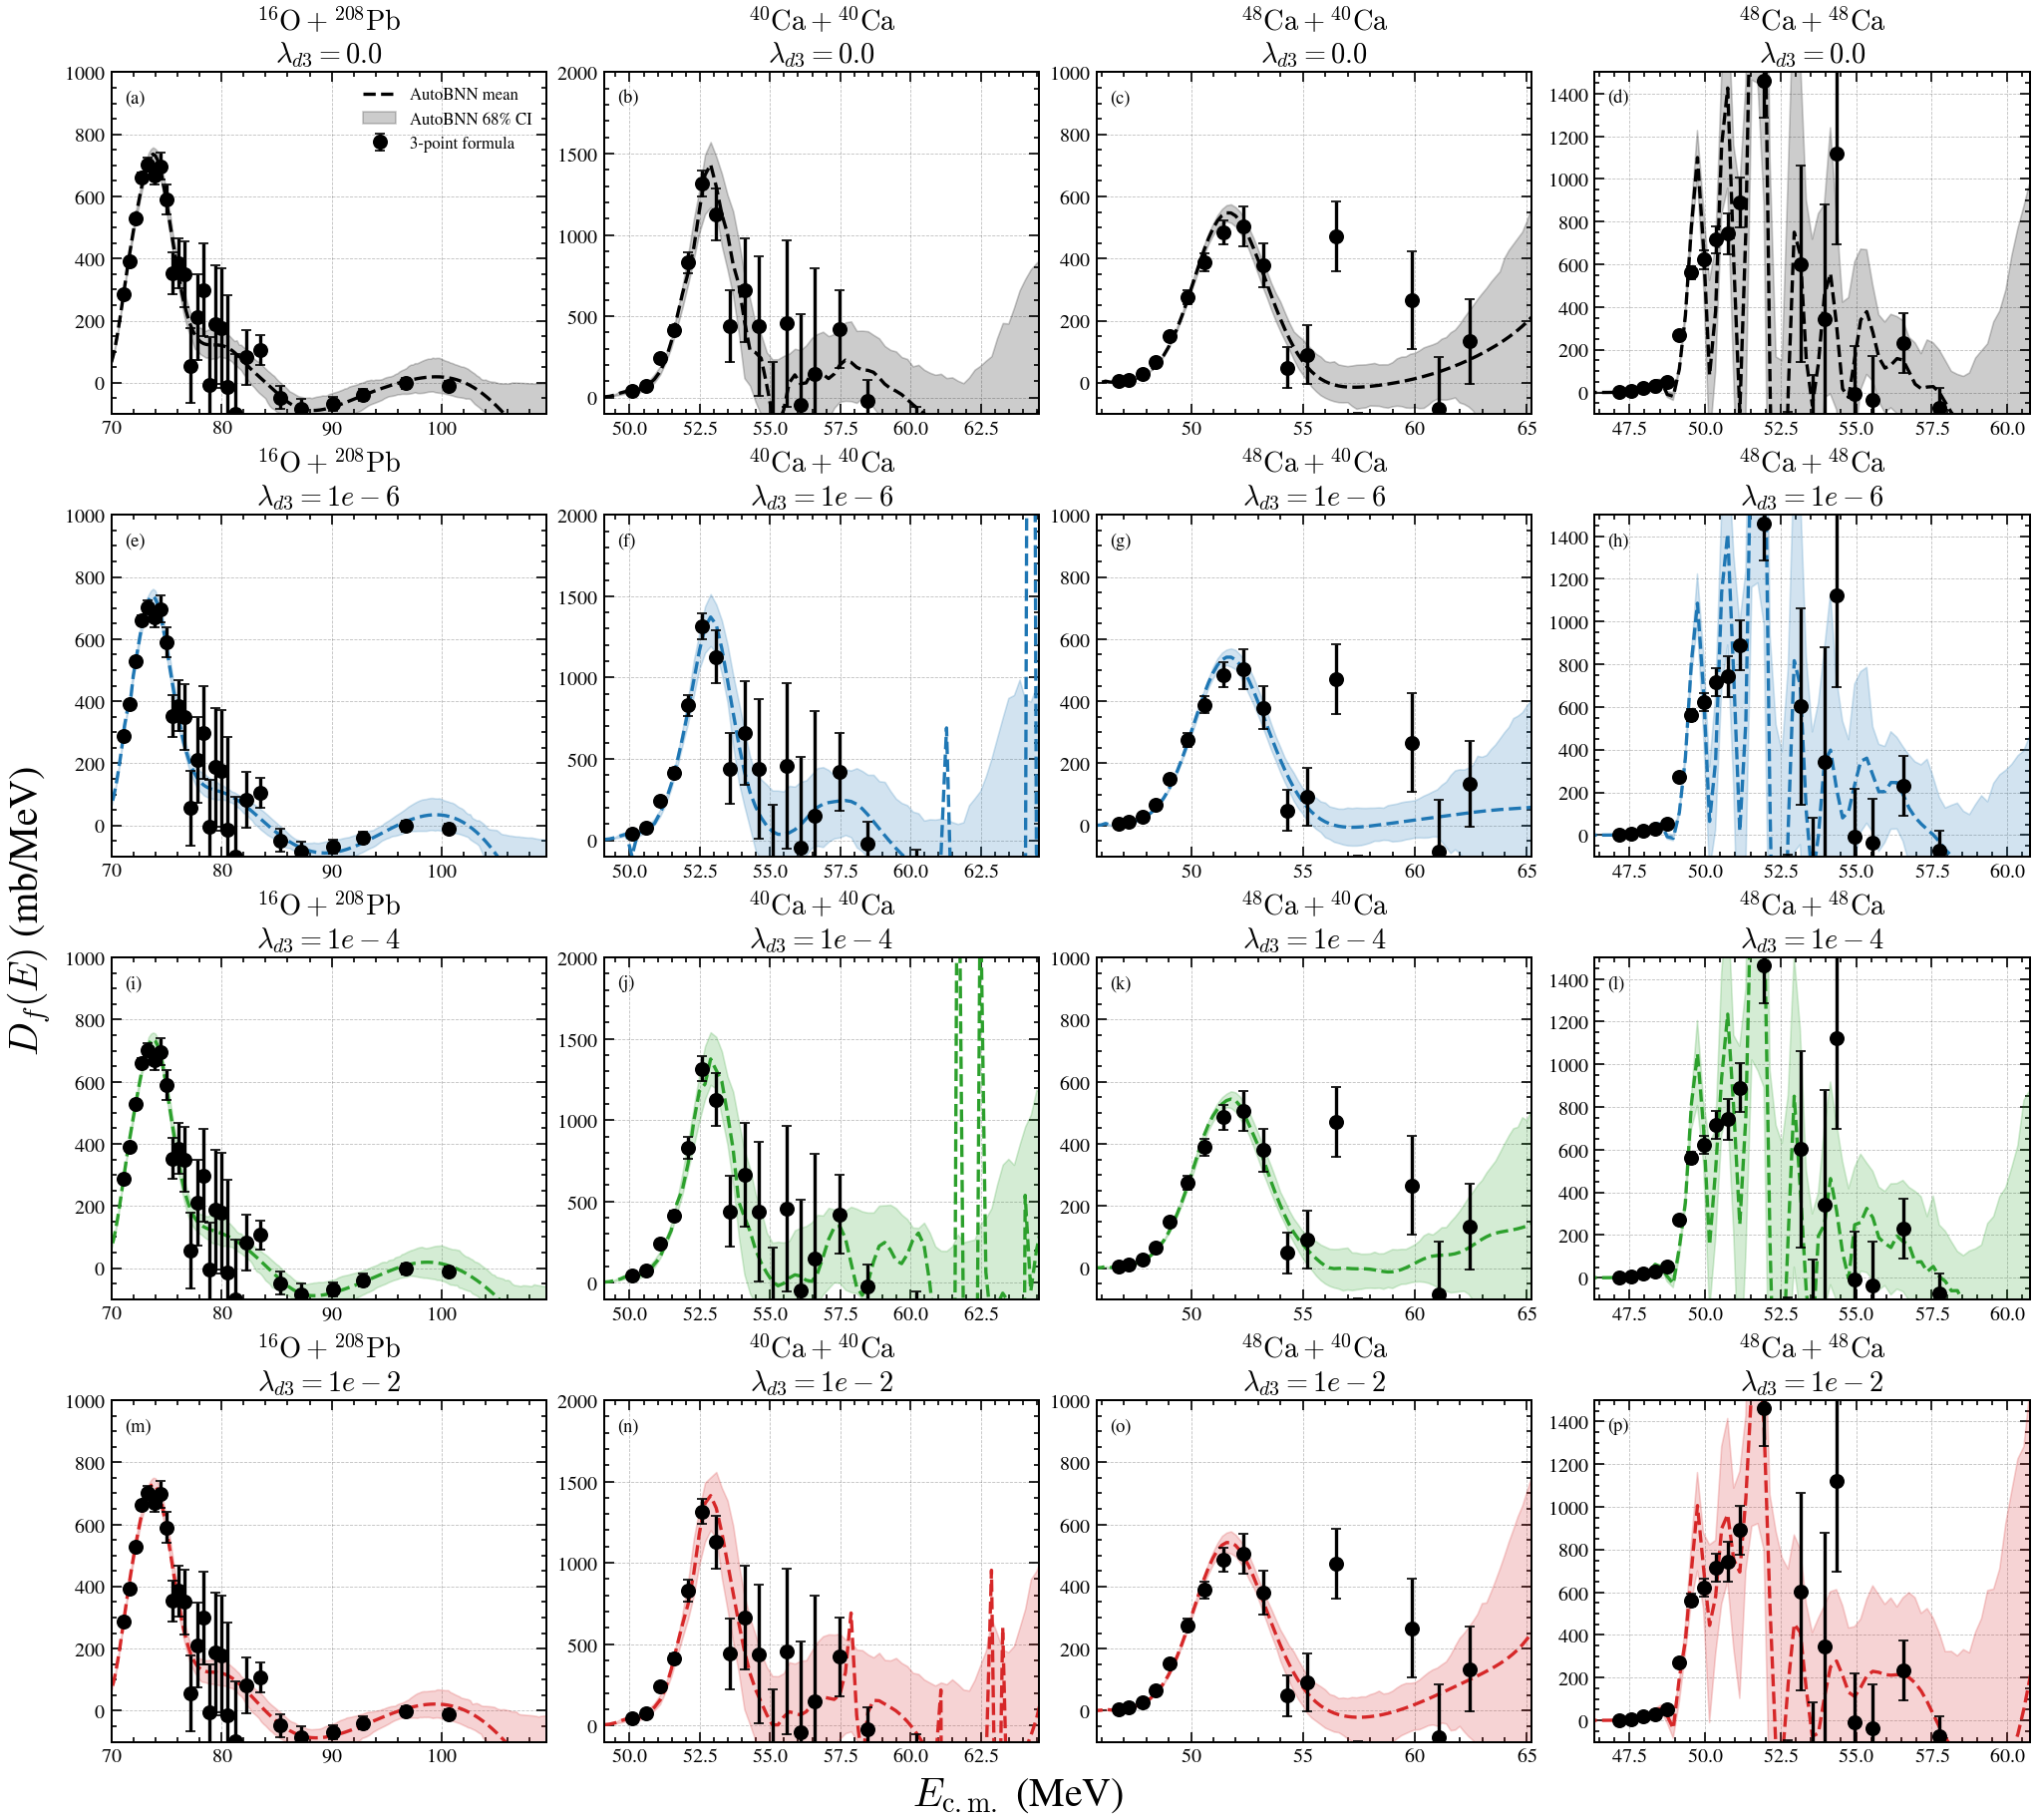

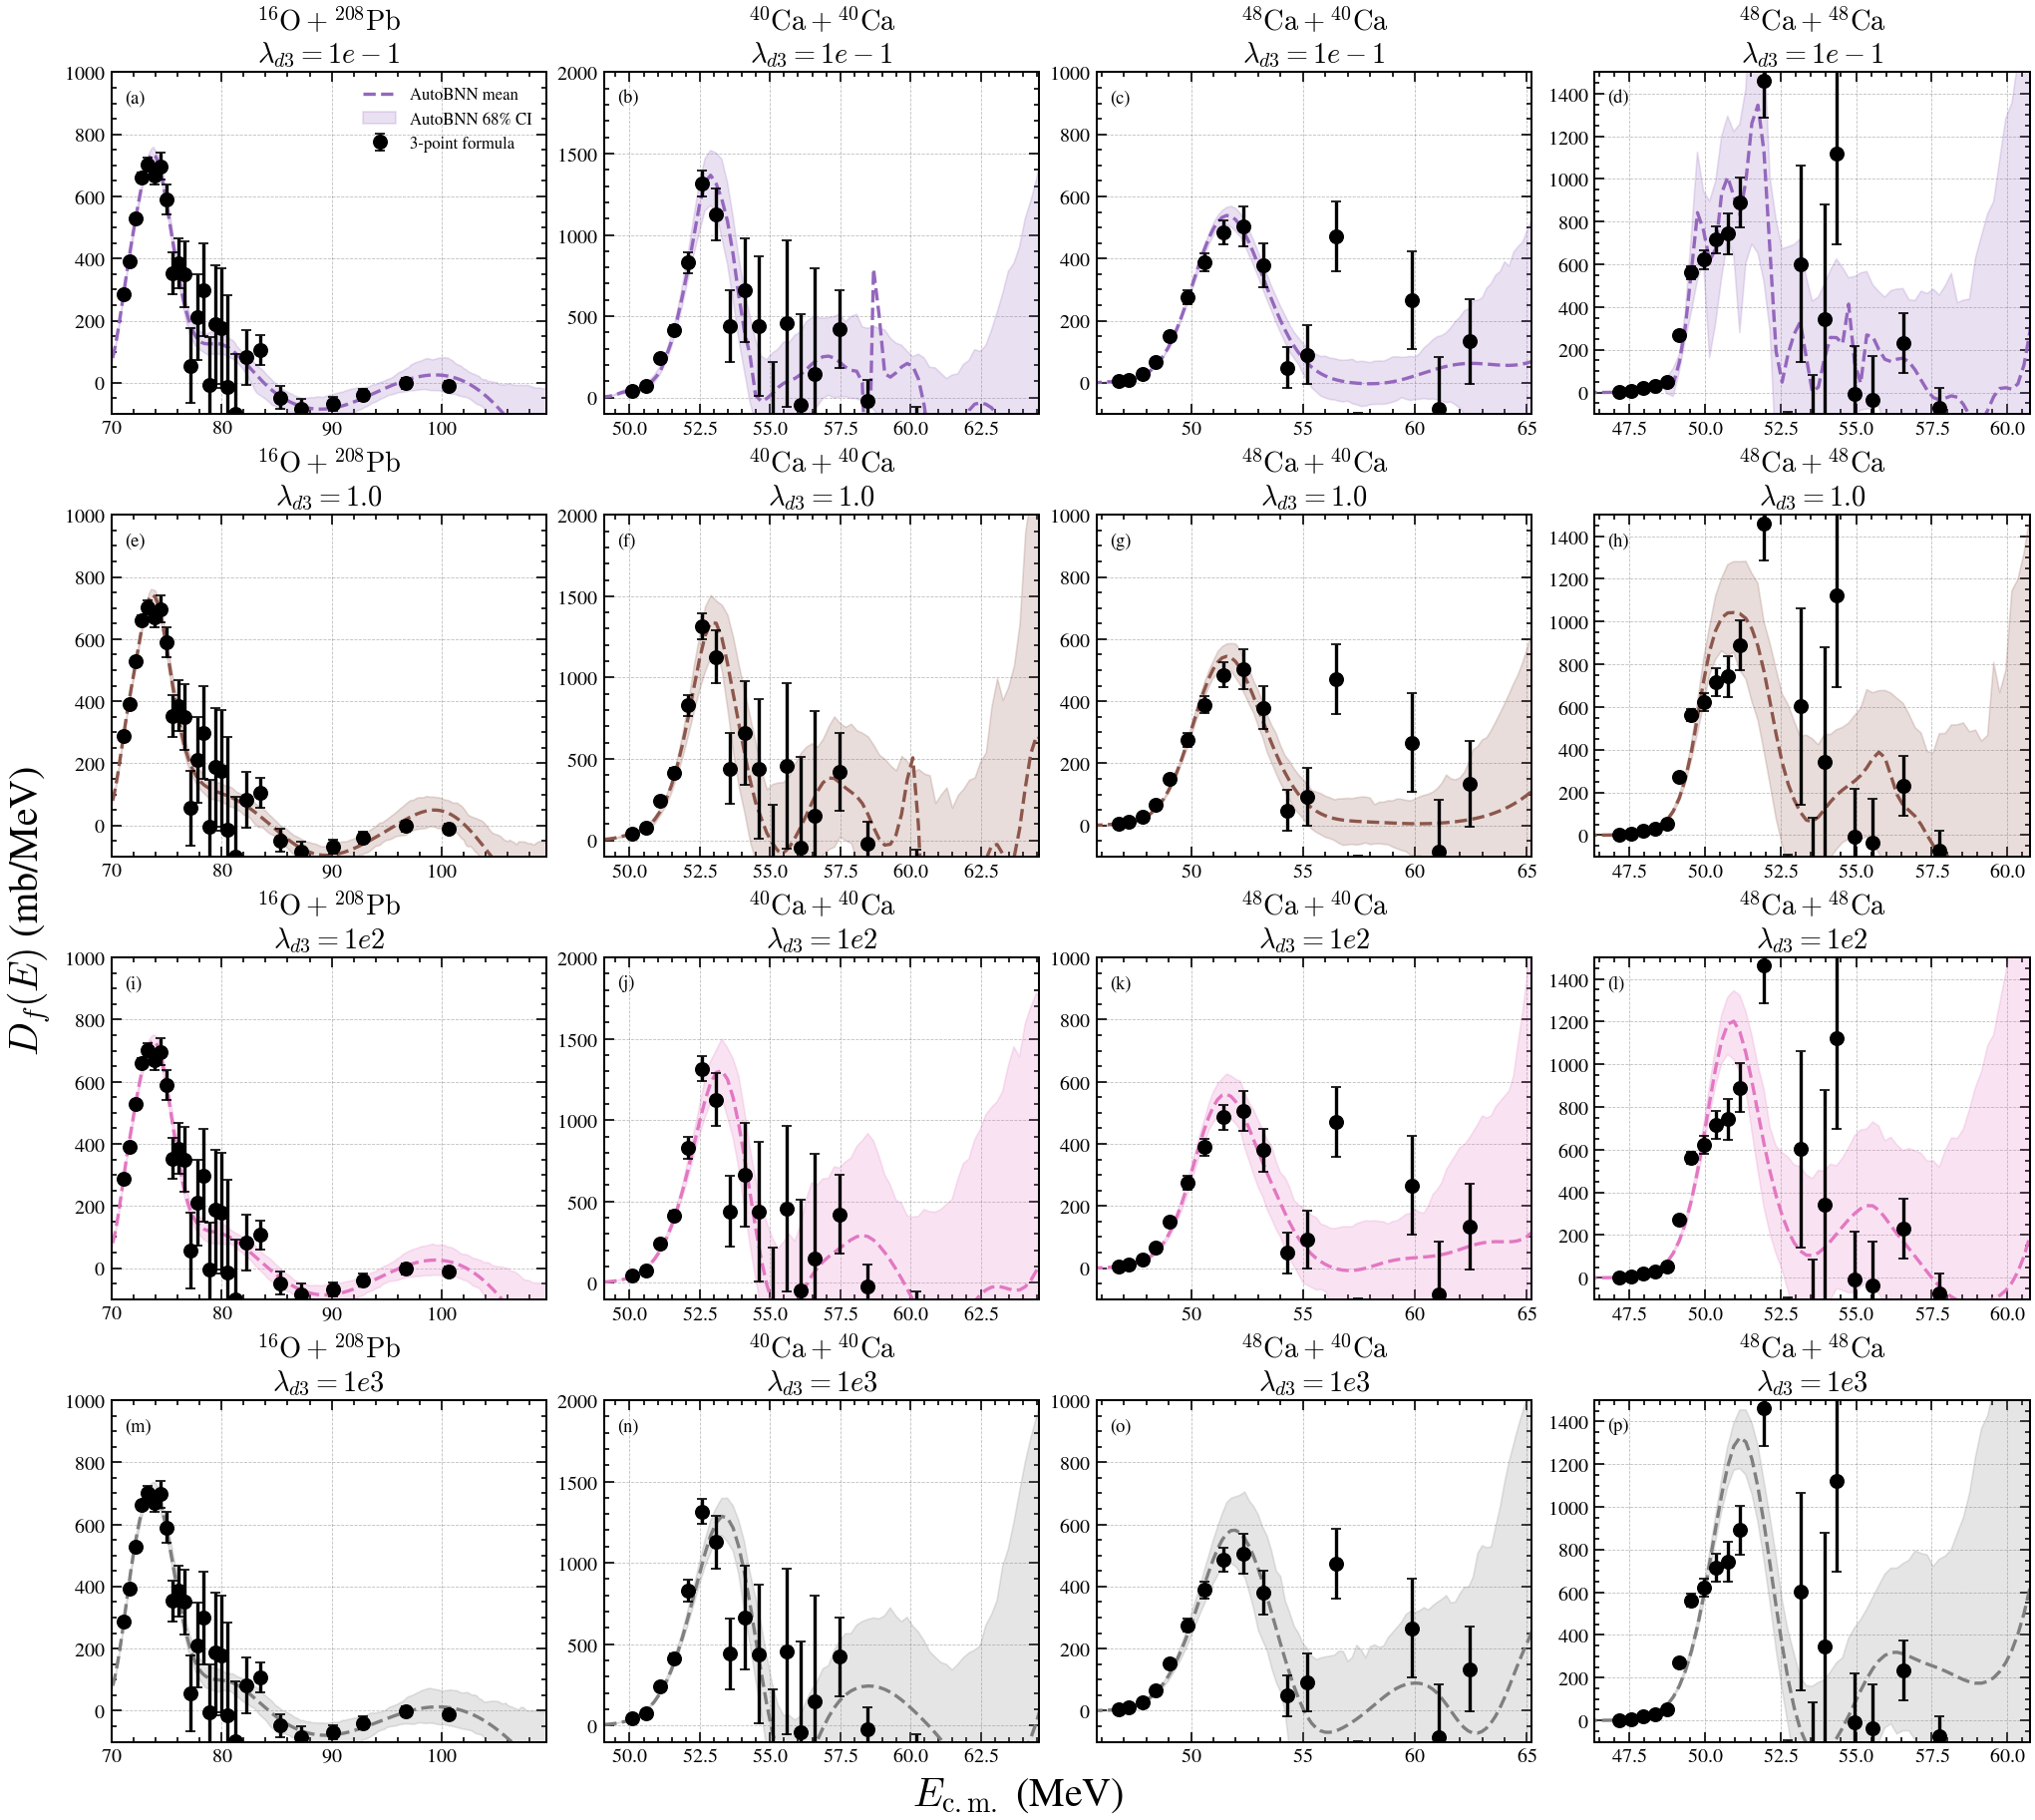

,dataset_idx,dataset,reaction_label,d3_lambda_tag,d3_lambda_label,preferred_run,chosen_group_name,used_fallback_group,num_available_groups,num_barrier_samples,h5_path
0,0,16O208PbMorton1999,$^{16}\mathrm{O} + ^{208}\mathrm{Pb}$,0,0.0,5,00000_run05,False,10,100,/mnt/ufs18/rs-021/ascsn/aaron-philip/barrier-e...
1,1,40Ca40CaMontagnoli2012,$^{40}\mathrm{Ca} + ^{40}\mathrm{Ca}$,0,0.0,6,00001_run06,False,10,100,/mnt/ufs18/rs-021/ascsn/aaron-philip/barrier-e...
2,2,48Ca40CaJiang2010,$^{48}\mathrm{Ca} + ^{40}\mathrm{Ca}$,0,0.0,2,00002_run02,False,10,100,/mnt/ufs18/rs-021/ascsn/aaron-philip/barrier-e...
3,3,48Ca48CaStefanini2009,$^{48}\mathrm{Ca} + ^{48}\mathrm{Ca}$,0,0.0,8,00003_run08,False,10,100,/mnt/ufs18/rs-021/ascsn/aaron-philip/barrier-e...
4,0,16O208PbMorton1999,$^{16}\mathrm{O} + ^{208}\mathrm{Pb}$,1e-6,1e-6,5,00000_run05,False,10,100,/mnt/ufs18/rs-021/ascsn/aaron-philip/barrier-e...
5,1,40Ca40CaMontagnoli2012,$^{40}\mathrm{Ca} + ^{40}\mathrm{Ca}$,1e-6,1e-6,6,00001_run06,False,10,100,/mnt/ufs18/rs-021/ascsn/aaron-philip/barrier-e...
6,2,48Ca40CaJiang2010,$^{48}\mathrm{Ca} + ^{40}\mathrm{Ca}$,1e-6,1e-6,2,00002_run02,False,10,100,/mnt/ufs18/rs-021/ascsn/aaron-philip/barrier-e...
7,3,48Ca48CaStefanini2009,$^{48}\mathrm{Ca} + ^{48}\mathrm{Ca}$,1e-6,1e-6,8,00003_run08,False,10,100,/mnt/ufs18/rs-021/ascsn/aaron-philip/barrier-e...
8,0,16O208PbMorton1999,$^{16}\mathrm{O} + ^{208}\mathrm{Pb}$,1e-4,1e-4,5,00000_run06,True,2,100,/mnt/ufs18/rs-021/ascsn/aaron-philip/barrier-e...
9,1,40Ca40CaMontagnoli2012,$^{40}\mathrm{Ca} + ^{40}\mathrm{Ca}$,1e-4,1e-4,6,00001_run06,False,10,100,/mnt/ufs18/rs-021/ascsn/aaron-philip/barrier-e...


In [3]:
weak_summary_df, weak_png, weak_pdf = build_grid(
    lambda_specs=weak_lambda_specs,
    figure_stem='experimental_d3_sweep_weak_barriers_grid',
)

strong_summary_df, strong_png, strong_pdf = build_grid(
    lambda_specs=strong_lambda_specs,
    figure_stem='experimental_d3_sweep_strong_barriers_grid',
)

summary_df = pd.concat([weak_summary_df, strong_summary_df], ignore_index=True)
summary_df

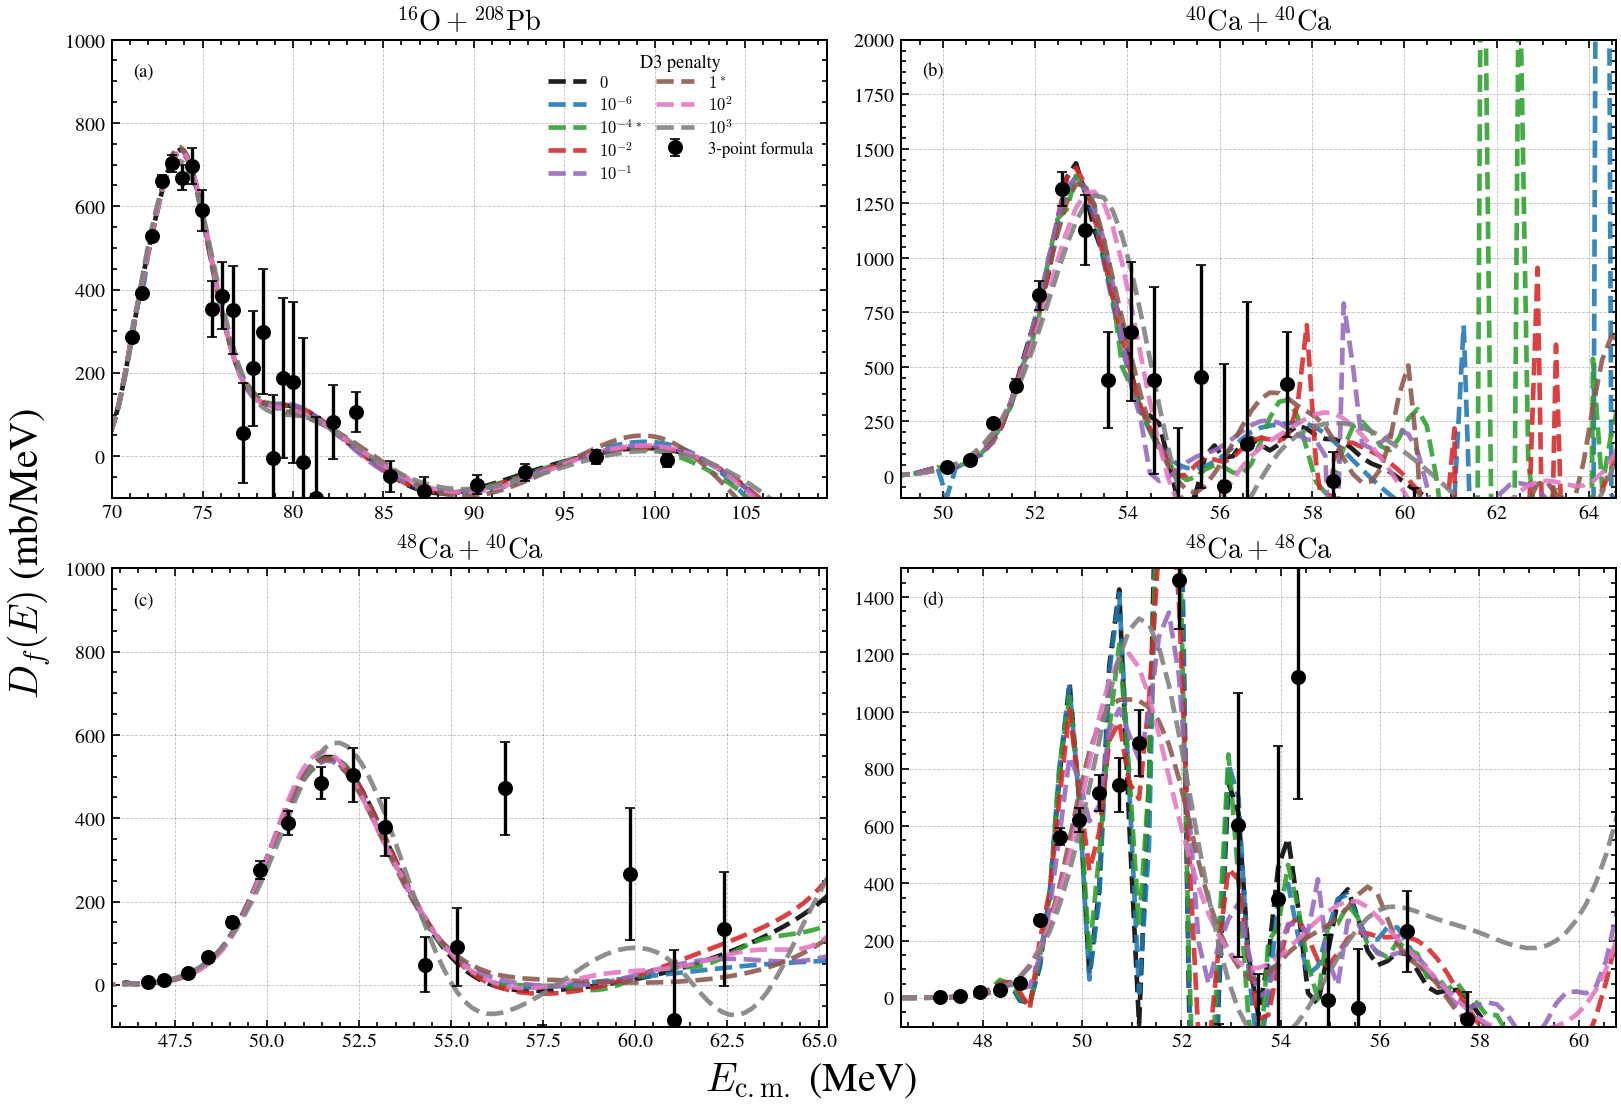

../../plots/experimental_d3_sweep_all_lambda_overlay.png
../../plots/experimental_d3_sweep_all_lambda_overlay.pdf


In [4]:
fig, axes = plt.subplots(2, 2, figsize=(13.5, 9.2), sharex=False, layout='constrained')
axes = axes.ravel()

for idx, (title, rxn_label, ax) in enumerate(zip(titles, reaction_labels, axes)):
    data_ref = None
    for lambda_tag, lambda_label in all_lambda_specs:
        payload = load_panel_payload(idx, title, lambda_tag, selected_sub_indices[title])
        data_ref = payload
        label = lambda_display_labels[lambda_label]
        if payload['used_fallback']:
            label += r'$^*$'
        ax.plot(
            payload['x'],
            payload['D_mean'],
            color=lambda_colors[lambda_label],
            linestyle=lambda_linestyles[lambda_label],
            linewidth=lambda_line_width,
            alpha=lambda_line_alpha,
            label=label,
        )

    ax.errorbar(
        data_ref['E_pts'],
        data_ref['D_pts'],
        yerr=data_ref['D_pts_err'],
        fmt='o',
        color='black',
        ms=8,
        lw=2,
        capsize=3,
        label='3-point formula',
    )

    ax.set_xlim(data_ref['E_data'].min(), data_ref['E_data'].max())
    ax.set_ylim(ylims[title])
    ax.set_title(rxn_label)

    ax.grid(True, alpha=0.25)
    ax.tick_params(direction='in', labelsize=12, length=4.5, width=1.0)

    ax.text(
        0.03, 0.95, f'({chr(97 + idx)})',
        transform=ax.transAxes,
        ha='left',
        va='top',
        fontsize=11,
    )

axes[0].legend(
    loc='upper right',
    frameon=False,
    fontsize=10,
    title='D3 penalty',
    title_fontsize=11,
    ncol=2,
    borderpad=0.35,
    labelspacing=0.25,
    columnspacing=0.8,
    handlelength=2.3,
)
fig.supxlabel(r'$E_{\mathrm{c.m.}}$ (MeV)', fontsize=24)
fig.supylabel(r'$D_f(E)$ (mb/MeV)', fontsize=24)

overlay_png = save_dir / 'experimental_d3_sweep_all_lambda_overlay.png'
overlay_pdf = save_dir / 'experimental_d3_sweep_all_lambda_overlay.pdf'
fig.savefig(overlay_png, bbox_inches='tight')
fig.savefig(overlay_pdf, bbox_inches='tight')
plt.show()
plt.close(fig)

print(overlay_png)
print(overlay_pdf)

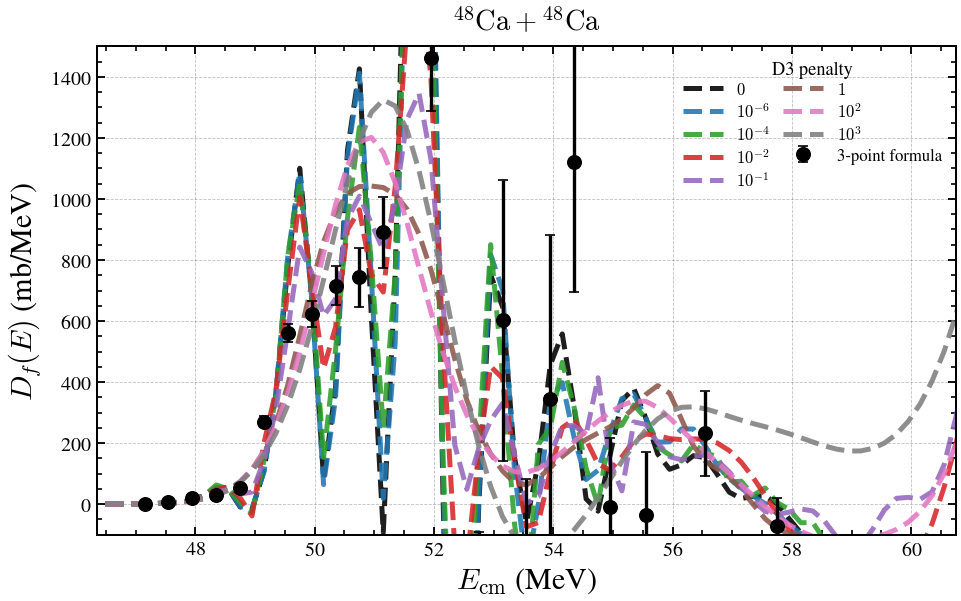

Saved:
../../plots/experimental_d3_sweep_weak_barriers_grid.png
../../plots/experimental_d3_sweep_weak_barriers_grid.pdf
../../plots/experimental_d3_sweep_strong_barriers_grid.png
../../plots/experimental_d3_sweep_strong_barriers_grid.pdf
../../plots/experimental_d3_sweep_all_lambda_overlay.png
../../plots/experimental_d3_sweep_all_lambda_overlay.pdf
../../plots/experimental_d3_sweep_stefanini_all_lambda_overlay.png
../../plots/experimental_d3_sweep_stefanini_all_lambda_overlay.pdf
../../plots/experimental_d3_sweep_selected_groups_all_lambda.csv


In [16]:
stef_idx = titles.index('48Ca48CaStefanini2009')
stef_title = titles[stef_idx]
stef_label = reaction_labels[stef_idx]

fig, ax = plt.subplots(1, 1, figsize=(8, 5), layout='constrained')

data_ref = None
for lambda_tag, lambda_label in all_lambda_specs:
    payload = load_panel_payload(stef_idx, stef_title, lambda_tag, selected_sub_indices[stef_title])
    data_ref = payload
    label = lambda_display_labels[lambda_label]
    ax.plot(
        payload['x'],
        payload['D_mean'],
        color=lambda_colors[lambda_label],
        linestyle=lambda_linestyles[lambda_label],
        linewidth=lambda_line_width + 0.2,
        alpha=lambda_line_alpha,
        label=label,
    )

ax.errorbar(
    data_ref['E_pts'],
    data_ref['D_pts'],
    yerr=data_ref['D_pts_err'],
    fmt='o',
    color='black',
    ms=8,
    lw=2,
    capsize=3,
    label='3-point formula',
)

ax.set_xlim(data_ref['E_data'].min(), data_ref['E_data'].max())
ax.set_ylim(ylims[stef_title])
ax.set_xlabel(r'$E_{\mathrm{cm}}$ (MeV)', fontsize=18)
ax.set_ylabel(r'$D_f(E)$ (mb/MeV)', fontsize=18)
ax.set_title(f'{stef_label}', fontsize=17, pad=10)
ax.grid(True, alpha=0.25)
ax.tick_params(direction='in', labelsize=12, length=5, width=1.1)
ax.legend(
    loc='upper right',
    frameon=False,
    fontsize=10,
    title='D3 penalty',
    title_fontsize=11,
    ncol=2,
    borderpad=0.35,
    labelspacing=0.25,
    columnspacing=0.8,
    handlelength=2.4,
)

stef_png = save_dir / 'experimental_d3_sweep_stefanini_all_lambda_overlay.png'
stef_pdf = save_dir / 'experimental_d3_sweep_stefanini_all_lambda_overlay.pdf'
fig.savefig(stef_png, bbox_inches='tight', dpi=300, pad_inches=0.25)
fig.savefig(stef_pdf, bbox_inches='tight', dpi=300, pad_inches=0.25)
plt.show()
plt.close(fig)

summary_csv = save_dir / 'experimental_d3_sweep_selected_groups_all_lambda.csv'
summary_df.to_csv(summary_csv, index=False)

print('Saved:')
print(weak_png)
print(weak_pdf)
print(strong_png)
print(strong_pdf)
print(overlay_png)
print(overlay_pdf)
print(stef_png)
print(stef_pdf)
print(summary_csv)

## Choosing the D3 Penalty on a Toy Problem

The experimental sweep above is the motivation: adding a D3 penalty visibly suppresses unstable barrier structure in the experimental fits. To choose the penalty strength in a more principled way, we then move to a controlled single-curve toy problem where the true barrier is known. The cells below summarize that toy sweep using barrier error and empirical coverage error, then plot the learned barriers across all toy datasets.


### Toy Sweep Metrics

Compute the barrier MAE and empirical coverage MAE summary for the `d3_sweep_single_curve` results. Lower values are better for both metrics; the win table counts which penalty is best on each of the 16 toy datasets.


In [6]:
from pathlib import Path
import re

import numpy as np
import pandas as pd


RESULTS_DIR = REPO_ROOT / "data" / "results" / "d3_sweep_single_curve"
PENALTY_ORDER = ["1", "1e1", "1e2"]
COVERAGE_LEVELS = [0, 25, 50, 68, 90, 95, 100]
FILENAME_RE = re.compile(
    r"(?P<dataset>.+)_curve0_bnn_soc_d3lam_(?P<penalty>1e2|1e1|1)\.h5\.csv$"
)

In [7]:
rows = []

for csv_path in sorted(RESULTS_DIR.glob("*.h5.csv")):
    match = FILENAME_RE.match(csv_path.name)
    if match is None:
        continue

    df = pd.read_csv(csv_path)
    df["barrier_MAE"] = pd.to_numeric(df["barrier_MAE"], errors="coerce")

    empirical_coverage = np.array(
        [pd.to_numeric(df[f"barrier_emp_cov_{level}"], errors="coerce").mean() * 100 for level in COVERAGE_LEVELS],
        dtype=float,
    )
    coverage_abs_error = np.abs(empirical_coverage - np.array(COVERAGE_LEVELS, dtype=float))

    rows.append(
        {
            "dataset": match.group("dataset"),
            "penalty": match.group("penalty"),
            "barrier_MAE": df["barrier_MAE"].mean(),
            "EC_MAE_pct": np.nanmean(coverage_abs_error),
        }
    )

metrics = pd.DataFrame(rows)

summary = (
    metrics.groupby("penalty")[["barrier_MAE", "EC_MAE_pct"]]
    .agg(["mean", "median", "std"])
    .loc[PENALTY_ORDER]
)

for metric in ["barrier_MAE", "EC_MAE_pct"]:
    metrics[f"{metric}_rank"] = metrics.groupby("dataset")[metric].rank(method="min", ascending=True)

wins = pd.DataFrame(
    {
        metric: (
            metrics.loc[metrics.groupby("dataset")[metric].idxmin(), "penalty"]
            .value_counts()
            .reindex(PENALTY_ORDER, fill_value=0)
        )
        for metric in ["barrier_MAE", "EC_MAE_pct"]
    }
)

print(f"Loaded {len(metrics)} CSV files across {metrics['dataset'].nunique()} datasets.")
print("\nSummary by D3 penalty:")
print(summary.to_string(float_format=lambda value: f"{value:.3f}"))
print("\nWins by metric, out of 16 datasets:")
print(wins.to_string())

Loaded 48 CSV files across 16 datasets.

Summary by D3 penalty:
        barrier_MAE                EC_MAE_pct             
               mean  median    std       mean median   std
penalty                                                   
1           123.362 117.596 69.335      6.344  5.924 3.235
1e1         101.462  81.319 71.555      5.606  4.286 3.388
1e2         115.475  85.659 72.707      7.535  5.622 5.406

Wins by metric, out of 16 datasets:
         barrier_MAE  EC_MAE_pct
penalty                         
1                  7           5
1e1                7           6
1e2                2           5


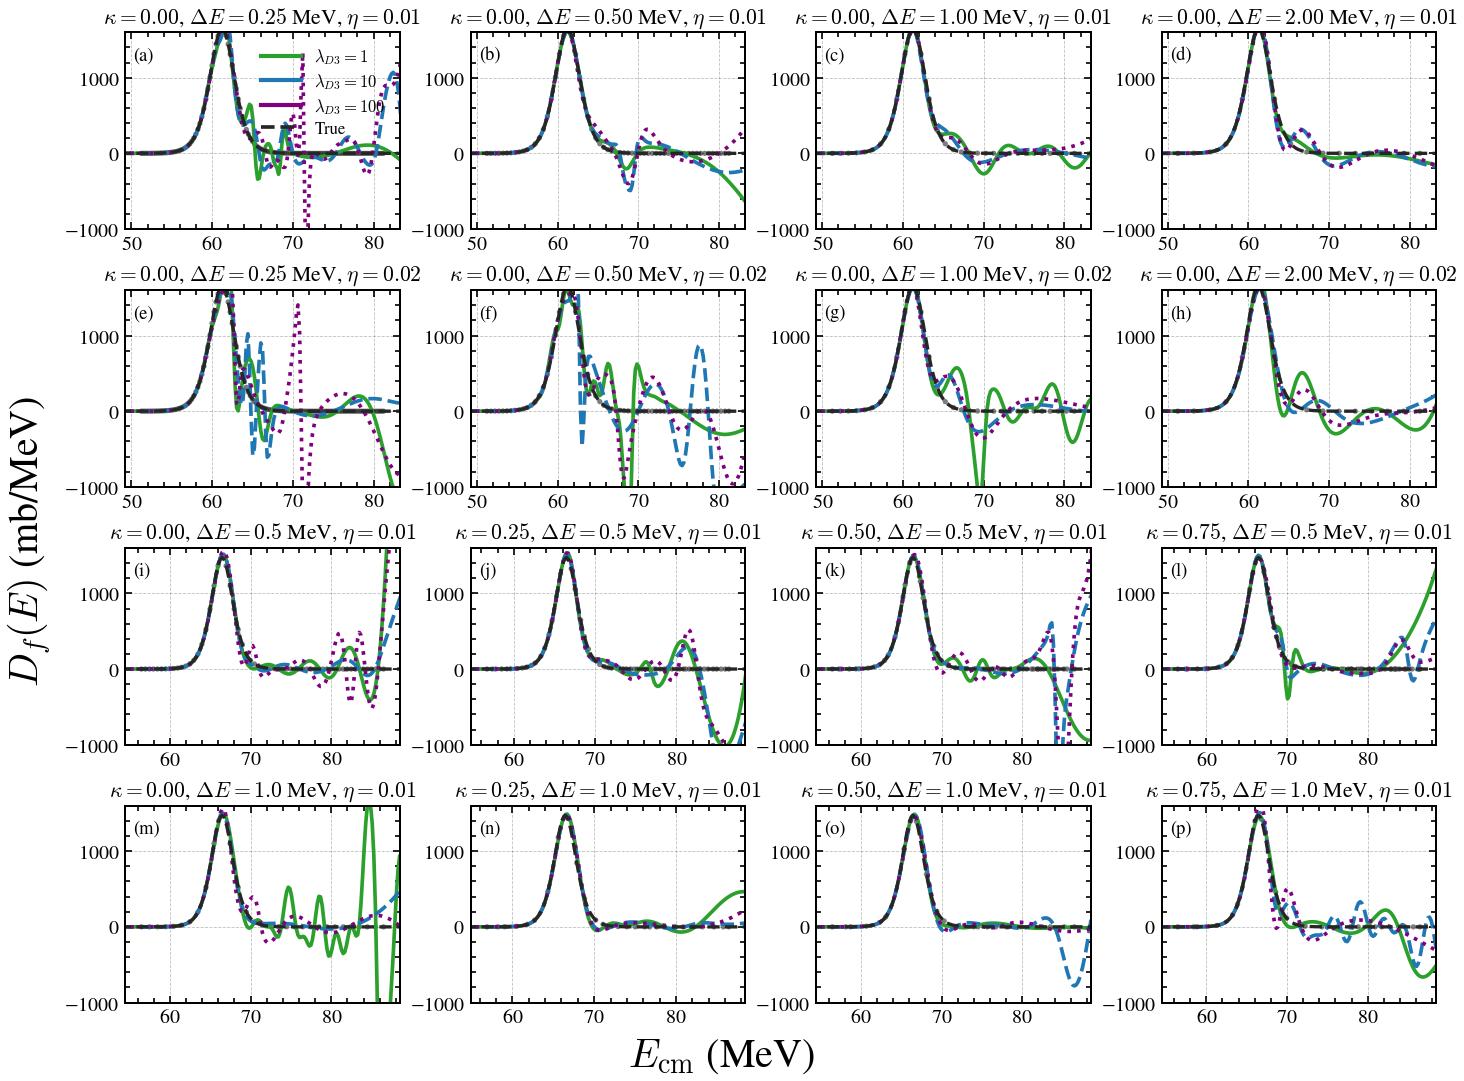

/mnt/ufs18/rs-021/ascsn/aaron-philip/barrier-extraction/plots/d3_penalty_16_dataset_barrier_curve_grid.png
/mnt/ufs18/rs-021/ascsn/aaron-philip/barrier-extraction/plots/d3_penalty_16_dataset_barrier_curve_grid.pdf


In [15]:
# Plot the trained barrier curves for each D3 penalty across all 16 datasets.
import h5py
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

try:
    import scienceplots
    plt.style.use(["science", "notebook", "ieee", "grid"])
except ModuleNotFoundError:
    plt.style.use("default")

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 11,
    "axes.labelsize": 18,
    "axes.titlesize": 17,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 10,
    "mathtext.fontset": "cm",
    "axes.linewidth": 1.2,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "figure.dpi": 120,
    "savefig.dpi": 300,
})

PENALTY_LABELS = {
    "1": r"$\lambda_{D3}=1$",
    "1e1": r"$\lambda_{D3}=10$",
    "1e2": r"$\lambda_{D3}=100$",
}
PENALTY_COLORS = {
    "1": "tab:green",
    "1e1": "tab:blue",
    "1e2": "purple",
}


def dataset_sort_key(dataset):
    res_match = re.match(r"res_(?P<res>[0-9.]+)MeV_noise(?P<noise>[0-9.]+)", dataset)
    if res_match:
        return (0, float(res_match.group("noise")), float(res_match.group("res")), dataset)
    cv_match = re.match(r"cv(?P<cv>[0-9.]+)_spacing(?P<spacing>[0-9.]+)", dataset)
    if cv_match:
        return (1, float(cv_match.group("spacing")), float(cv_match.group("cv")), dataset)
    return (2, dataset)


def dataset_panel_title(dataset):
    res_match = re.match(r"res_(?P<res>[0-9.]+)MeV_noise(?P<noise>[0-9.]+)", dataset)
    if res_match:
        return rf"$\kappa=0.00$, $\Delta E={float(res_match.group('res')):.2f}$ MeV, $\eta={float(res_match.group('noise')):.2f}$"
    cv_match = re.match(r"cv(?P<cv>[0-9.]+)_spacing(?P<spacing>[0-9.]+)", dataset)
    if cv_match:
        return rf"$\kappa={float(cv_match.group('cv')):.2f}$, $\Delta E={float(cv_match.group('spacing')):.1f}$ MeV, $\eta=0.01$"
    return dataset


def d3_h5_path(dataset, penalty):
    return RESULTS_DIR / f"{dataset}_curve0_bnn_soc_d3lam_{penalty}.h5"


def first_group(h5_file):
    return h5_file[sorted(h5_file.keys())[0]]


def wong_sigma(E, E0, R0, hbarw):
    return 10.0 * (0.5 * R0**2 * hbarw / E) * np.log(
        1.0 + np.exp(2.0 * np.pi * (E - E0) / hbarw)
    )


def barrier_from_sigma(E, sigma):
    return np.gradient(np.gradient(E * sigma, E, edge_order=2), E, edge_order=2)


def load_d3_curve(dataset, penalty):
    with h5py.File(d3_h5_path(dataset, penalty), "r") as f:
        grp = first_group(f)
        x_pred = grp["x_pred"][()]
        d2_samples = grp["d2_samples"][()]
        E_data = grp["E_data"][()]
        attrs = dict(grp.attrs)

    E0 = float(attrs["E0_true"])
    R0 = float(attrs["R0_true"])
    hw = float(attrs["hw_true"])
    true_barrier = barrier_from_sigma(x_pred, wong_sigma(x_pred, E0, R0, hw))

    return {
        "x_pred": x_pred,
        "d_mean": np.nanmean(d2_samples, axis=0),
        "d_low": np.nanpercentile(d2_samples, 2.5, axis=0),
        "d_high": np.nanpercentile(d2_samples, 97.5, axis=0),
        "E_data": E_data,
        "true_barrier": true_barrier,
    }


datasets = sorted(metrics["dataset"].unique(), key=dataset_sort_key)
if len(datasets) != 16:
    raise ValueError(f"Expected 16 datasets, found {len(datasets)}")

fig, axes = plt.subplots(4, 4, figsize=(12.0, 9), sharex=False, sharey=False, constrained_layout=True)
axes = axes.ravel()

for idx, (dataset, ax) in enumerate(zip(datasets, axes)):
    ref = None
    for penalty in PENALTY_ORDER:
        curve = load_d3_curve(dataset, penalty)
        ref = curve
        ax.plot(
            curve["x_pred"],
            curve["d_mean"],
            color=PENALTY_COLORS[penalty],
            lw=2.2,
            label=PENALTY_LABELS[penalty],
        )

    ax.plot(ref["x_pred"], ref["true_barrier"], color="0.15", lw=2.0, ls="--", label="True")
    ax.scatter(
        ref["E_data"],
        np.interp(ref["E_data"], ref["x_pred"], ref["true_barrier"]),
        s=10,
        color="0.15",
        alpha=0.6,
        edgecolor="none",
    )
    ax.set_title(dataset_panel_title(dataset), fontsize=13)
    ax.set_xlim(ref["E_data"].min() - 2.0, ref["E_data"].max() + 2.0)
    ax.set_ylim(-1000, 1600)
    ax.tick_params(direction="in", length=4, width=1.0)
    ax.text(
        0.03,
        0.93,
        f"({chr(97 + idx)})",
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=11,
    )

fig.supxlabel(r"$E_{\mathrm{cm}}$ (MeV)", fontsize=24)
fig.supylabel(r"$D_f(E)$ (mb/MeV)", fontsize=24)

handles = [
    Line2D([0], [0], color=PENALTY_COLORS[penalty], lw=2.5, label=PENALTY_LABELS[penalty])
    for penalty in PENALTY_ORDER
]
handles.append(Line2D([0], [0], color="0.15", lw=2.2, ls="--", label="True"))
axes[0].legend(
    handles=handles,
    loc="upper right",
    frameon=False,
    borderpad=0.35,
    labelspacing=0.3,
    handlelength=2.4,
)

#fig.suptitle("D3 penalty sweep: 16 Wong curves", fontsize=17)
out_dir = REPO_ROOT / "plots"
out_dir.mkdir(parents=True, exist_ok=True)
curve_grid_png = out_dir / "d3_penalty_16_dataset_barrier_curve_grid.png"
curve_grid_pdf = out_dir / "d3_penalty_16_dataset_barrier_curve_grid.pdf"
fig.savefig(curve_grid_png, dpi=300, bbox_inches="tight")
fig.savefig(curve_grid_pdf, bbox_inches="tight")
plt.show()
plt.close(fig)

print(curve_grid_png)
print(curve_grid_pdf)
